# プログラムの実行効率を上げる

Python は動的な言語なので、開発は楽ですが、実行速度は遅くなりがちです。計算の多いプログラムでは、Python と C で数十倍から数百倍の差が出ることがあります。

そのため、NumPy や SciPy のような、C などで書かれた拡張ライブラリを呼び出し、Python のループで数値計算を書かないようにします。既存のライブラリで足りない部分は、速い言語で計算の核心だけを書き、Python から呼ぶ形にします。開発の速さと計算の速さを両立できます。

ただし C で拡張ライブラリを書くと、Python の便利さは失われます。引数を手で解析し、参照カウントを管理し、Python/C API を覚える必要があります。本来の問題に集中できません。

この章では、Julia 集合の計算を題材に、CFFI、ctypes、Cython、Numba で計算を速くする方法を比べます。それぞれの詳しい使い方は、後の章で説明します。

In [1]:
import numpy as np
import numba as nb
import cmath
import random
import helper.matplotlib
from matplotlib import pyplot as plt

## Python の計算が遅い理由

理由は 2 つあります。

1. Python のオブジェクトは C のデータを包んでいます。包まれたデータのアドレスは連続しないので、CPU のキャッシュが効きません。NumPy の `ndarray` は、この問題を解決します。
2. Python のプログラムは Python 仮想マシンで動きます。小さな計算でも、Python/C API の関数をいくつも呼びます。ループの中で Python の関数を何度も呼ぶと、呼び出しの費用が計算そのものより大きくなります。NumPy の `ufunc` は、ループを C で書くことでこれを解決します。

### Python のオブジェクト

Python では、整数もオブジェクトとしてメモリに置かれます。型や参照カウントの情報も一緒に持つためです。次のプログラムで、Python の整数が 28 バイトを占めることが分かります。C などの言語なら、16 ビット、32 ビット、64 ビットの整数から必要な大きさを選べます。

In [2]:
import sys  # 実行環境の情報

aint = 10000
sys.getsizeof(aint)

28

`sys.getrefcount()` で、オブジェクトの参照カウントを調べられます。次のプログラムは、`aint` の参照カウントを表示し、リスト `alist` で 10 回参照し、`del` でリストを消します。出力から、参照カウントが変わることが分かります。

このことから、Python のリストは他のオブジェクトへの参照を持つだけだと分かります。整数のリストでも、整数のデータそのものは連続したメモリにありません。CPU のキャッシュには不利です。

In [3]:
print(sys.getrefcount(aint))  # 変数からの参照 1 つ
alist = [aint] * 10            # リストが 10 個の参照を持つ
print(sys.getrefcount(aint))  # 参照が増える
del alist
print(sys.getrefcount(aint))  # 元に戻る

2
12
2


NumPy の配列は、データを 1 つの連続したメモリに置きます。ただし、要素を 1 つ取り出して Python で計算するには、その要素を Python のオブジェクトに包み直す必要があります。この処理をボクシング(boxing)、その逆をアンボクシング(unboxing)と呼びます。

次の例では、リストから取った要素はオブジェクトそのものなので、2 回取っても同じオブジェクトです。配列から取った要素は、毎回ボクシングされて新しいオブジェクトになります。`is` で、2 つの参照が同じオブジェクトを指すかを調べられます。参照とオブジェクトの関係は次の図のとおりです。Python は計算の前に、参照の解決やボクシング、アンボクシングを行います。これが遅い理由の 1 つです。

![オブジェクトの参照とボクシング](images/python-reference.svg)

In [4]:
import numpy as np

alist = [1000, 1001, 1002]  # リストはオブジェクトへの参照を持つ
arr = np.array(alist)
a = alist[1]
b = alist[1]
c = arr[1]
d = arr[1]
print(a is b)
print(c is d)

True
False


### Python のインタプリタ

Python のプログラムは、Python 仮想マシンで動きます。実行するときは、まずソースコードをバイトコードにコンパイルし、そのバイトコードをインタプリタが実行します。このインタプリタはスタックマシンで、スタックに状態を置きます。

`dis` モジュールで、関数のバイトコードを表示できます。次のプログラムは `hypot()` のバイトコードです。`(a**2 + b**2) ** 0.5` の計算に、`RESUME` から `RETURN_VALUE` まで 11 個のバイトコードを実行します。

* `LOAD_FAST_BORROW` は、ローカル変数の値をスタックに積みます(借用なので参照カウントを増やしません)。
* `LOAD_SMALL_INT` と `LOAD_CONST` は、定数をスタックに積みます。
* `BINARY_OP` は、スタックの上 2 つで演算を行い、結果を積みます。3.11 以降は `BINARY_ADD` や `BINARY_POWER` のような命令が 1 つにまとまり、引数の番号で演算の種類を選びます。`8` が `**`、`0` が `+` です。
* `RETURN_VALUE` は、スタックの上の値を返します。

In [5]:
import dis


def hypot(a, b):  # 2 点間の距離
    return (a**2 + b**2) ** 0.5


dis.dis(hypot)

  4           RESUME                   0

  5           LOAD_FAST_BORROW         0 (a)
              LOAD_SMALL_INT           2
              BINARY_OP                8 (**)
              LOAD_FAST_BORROW         1 (b)
              LOAD_SMALL_INT           2
              BINARY_OP                8 (**)
              BINARY_OP                0 (+)
              LOAD_CONST               1 (0.5)
              BINARY_OP                8 (**)
              RETURN_VALUE


バイトコードを実行する C のプログラムは `ceval.c` です。3.11 までは、バイトコードごとの処理が `case TARGET(...)` として並んでいました。3.12 以降は `Python/bytecodes.c` に処理を書き、ビルダーが `generated_cases.c.h` を生成する方式に変わりました。ソースは次のリンクから読めます。

:::{seealso}
https://github.com/python/cpython/blob/master/Python/ceval.c

Python バイトコードを実行する C 言語のソースプログラム
:::

次に、3.10 の `LOAD_FAST` と `BINARY_ADD` の処理を示します。バイトコード 1 つが、C のコードのまとまった部分に対応することが分かります。3.14 では `BINARY_ADD` は `BINARY_OP` に統合され、この処理は `generated_cases.c.h` に生成されます。

加算のコードは、まず対象が文字列かどうかを調べ、文字列なら連結の関数 `unicode_concatenate()` を、そうでなければ `PyNumber_Add()` を呼びます。`PyNumber_Add()` の中でも、2 つの浮動小数点数の和を出すまでに多くの処理が走ります。

```c
case TARGET(LOAD_FAST): {
    PyObject *value = GETLOCAL(oparg);
    if (value == NULL) {
        format_exc_check_arg(tstate, PyExc_UnboundLocalError,
                             UNBOUNDLOCAL_ERROR_MSG,
                             PyTuple_GetItem(co->co_varnames, oparg));
        goto error;
    }
    Py_INCREF(value);
    PUSH(value);
    FAST_DISPATCH();
}
```

```c
case TARGET(BINARY_ADD): {
    PyObject *right = POP();
    PyObject *left = TOP();
    PyObject *sum;
    if (PyUnicode_CheckExact(left) &&
             PyUnicode_CheckExact(right)) {
        sum = unicode_concatenate(tstate, left, right, f, next_instr);
    }
    else {
        sum = PyNumber_Add(left, right);
        Py_DECREF(left);
    }
    Py_DECREF(right);
    SET_TOP(sum);
    if (sum == NULL)
        goto error;
    DISPATCH();
}
```

## C コンパイラの設定

計算を速くするには、コンパイラでマシンコードに変換します。本書では cffi、Cython、Numba の 3 つを使います。まず、拡張ライブラリを入れます。

```
conda install cython numba cffi
```

`cffi` や `Cython` で拡張モジュールを作るには、使う C コンパイラを決めておきます。Python は `distutils` でコンパイルし、`distutils` は次の 3 つの設定ファイルを、優先順位の高い順に読みます。

1. `distutils` モジュールのパスにある `distutils.cfg`
2. ホームディレクトリの `pydistutils.cfg`
3. カレントディレクトリの `setup.cfg`

次のプログラムは、この 3 つのファイルのパスを表示し、`parse_config_files()` で設定を読みます。`build` コマンドの `compiler` が `mingw32` になっているのは、`setup.cfg` の設定を読んだためです。ファイルの中身は次のとおりです。

```
[build]
compiler=mingw32
```

:::{seealso}
https://github.com/niXman/mingw-builds-binaries

MinGW-W64 をインストールしたら、`gcc.exe` のあるフォルダを PATH に追加してください。この本の環境(pixi)では、MinGW の `gcc` がすでに PATH にあります。
:::

In [6]:
from distutils.core import Distribution

dist = Distribution()
print(dist.find_config_files())
dist.parse_config_files()
dist.command_options

['setup.cfg']


{'build': {'compiler': ('setup.cfg', 'mingw32')},
 'build_ext': {'compiler': ('setup.cfg', 'mingw32')}}

## Julia 集合の計算を速くする

Julia 集合は、複素平面上でフラクタルになる点の集まりです。次の式を繰り返して得られます。

$$ f_{c}(z)=z^{2}+c$$

複素数 $c$ を固定し、複素数 $z_0$ から始めると、次の列ができます。

$$ z_{0},f_{c}(z_{0}),f_{c}(f_{c}(z_{0})),f_{c}(f_{c}(f_{c}(z_{0}))),\ldots .$$

この列は無限に発散するか、ある範囲にとどまります。発散しない $z_0$ の集合が Julia 集合です。

集合上の点は、ランダムな逆反復で計算できます。$z_n$ と $c$ はどちらも複素数で、手順は次のとおりです。

1. $z_{0} ={\frac  {1+{\sqrt  {1-4c}}}{2}}$ で初期化する。
2. $z_{n} = \sqrt{z_{n-1} - c}$ を計算する。
3. 2 分の 1 の確率で、$z_{n}$ の符号を変える。
4. $z_{n}$ を保存し、2 に戻る。

この反復は NumPy の `ufunc` では書けず、ループで 1 回ずつ計算します。次の `py_julia_set()` がその実装で、`cmath` は Python 標準ライブラリの複素数用のモジュールです。

In [7]:
import numpy as np
import cmath
import random


def py_julia_set(c, n):
    z = (1 + cmath.sqrt(1 - 4 * c)) / 2
    res = np.zeros(n, dtype=np.complex128)  # 結果を入れる配列
    for i in range(n):
        z = cmath.sqrt(z - c)
        if random.randint(0, 1):
            z = -z
        res[i] = z
    return res


c = -0.512511498387847167 + 0.521295573094847167j
%timeit py_julia_set(c, 100000)
z = py_julia_set(c, 100000)

74.2 ms ± 9.03 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


`z` は複素数の配列です。次のコードは、実部と虚部を取り出し、`histogram2d()` で 2 次元のヒストグラムにして描きます。

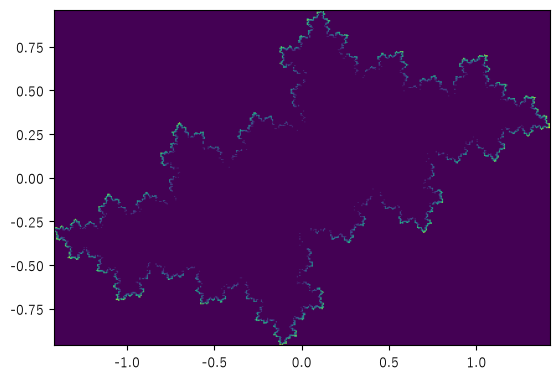

In [8]:
counts, xe, ye = np.histogram2d(z.real, z.imag, bins=400)  # 2 次元ヒストグラム
plt.imshow(np.log(counts.T + 1), extent=[xe[0], xe[-1], ye[0], ye[-1]]);

### C の関数を呼ぶ

次の `julia.c` の `julia_set()` は、`py_julia_set()` と同じ計算を C で書いたものです。CFFI と ctypes は複素数を引数にできないので、`cr` と `ci` で $c$ の実部と虚部を別々に渡します。C の関数の中では NumPy 配列を作れないので、結果は複素数のポインタ `arr` に書き、`n` がその長さです。

In [9]:
%%file julia.c
#include <complex.h>
#include <stdlib.h>

void julia_set(double cr, double ci, double complex * arr, int n)
{
    int i;
    double complex c;
    double complex z;
    c = cr + ci * I;
    z = 0.0;
    for(i=0; i<n; i++){
        z = csqrt(z - c);
        if(rand() & 0x01){
            z = -z;
        }
        arr[i] = z;
    }
}

Overwriting julia.c


次のコマンドで、`julia.c` をダイナミックリンクライブラリ `julia.dll` にコンパイルし、中の関数をエクスポートします。

In [10]:
!gcc -shared julia.c -o julia.dll

CFFI で `julia.dll` の `julia_set()` を呼びます。

❶ まず `FFI` オブジェクトを作ります。FFI は Foreign Function Interface(外部関数インターフェース)の略です。❷ `cdef()` で、ライブラリの関数の型を宣言します。CFFI は複素数を扱えないので、`arr` は `double *` として宣言します。ポインタはアドレスを渡すだけなので、呼ぶときの型は問題になりません。`julia_set()` の中では、`arr` のアドレスを複素数のポインタとして扱います。❸ `dlopen()` で `julia.dll` を開き、`cdef()` で宣言した関数を呼べるオブジェクト `lib` を得ます。

❹ 呼ぶとき、CFFI は Python のオブジェクトを C の型に変換します。`float` は `double`、`int` は `int` になります。NumPy 配列は自動で変換されないので、`ffi.from_buffer()` で配列のデータへのポインタにします。型は第 1 引数で指定します。C の関数は配列の `shape` や `strides` を知らないので、渡す配列は 1 次元で連続している必要があります。

In [11]:
import cffi

ffi = cffi.FFI()  #❶
ffi.cdef("void julia_set(double cr, double ci, double * arr, int n);")  #❷
lib = ffi.dlopen("julia.dll")  #❸


def cffi_julia_set(c, n):
    res = np.zeros(n, dtype=np.complex128)  # C の関数が書き込む配列
    lib.julia_set(c.real, c.imag, ffi.from_buffer("double *", res), len(res))  #❹
    return res


%timeit cffi_julia_set(c, 100000)

6.49 ms ± 511 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


Python 標準ライブラリの ctypes でも呼べます。手順は CFFI と逆で、まず `ctypes.cdll.LoadLibrary()` でライブラリを開き、関数の `argtypes` と `restype` で引数と戻り値の型を決めます。NumPy 配列は `ctypes.data_as()` でポインタに変換できます。

In [12]:
import ctypes
from ctypes import c_double, POINTER, c_int

dll = ctypes.cdll.LoadLibrary("julia.dll")  # ライブラリを開く
dll.julia_set.argtypes = [c_double, c_double, POINTER(c_double), c_int]
dll.julia_set.restype = None
res = np.zeros(10000, np.complex128)
dll.julia_set(c.real, c.imag, res.ctypes.data_as(POINTER(c_double)), len(res))

### Cython で速くする

Cython は、Python に似た書き方で C の拡張モジュールを書くための言語です。構文はほとんど Python と同じで、C の関数を呼ぶ記述や、変数の型の指定が足されています。Cython のコードを C に変換し、C コンパイラで拡張モジュールにします。C の速さと Python の柔軟さを両立できます。

Cython は `cimport`、`cdef`、`extern from` などのキーワードを足し、`wraparound`、`boundscheck` などの指示でコンパイラの動作を決めます。`cdef` で C の型の変数や関数を定義すれば、Python/C API を呼ばないループにコンパイルされます。

Notebook では、`%%cython` マジックで拡張モジュールをコンパイルし、そのまま関数を読み込めます。使う前に `%load_ext cython` でマジックを読み込みます。次のプログラムは `%%cython` で始まり、`cy_julia_set()` の中で NumPy の `zeros()` と、C の `csqrt()`、`rand()` を呼んでいます。

In [13]:
import helper.cython
%load_ext helper.cython

In [14]:
%%cython --compile-args=-w
# distutils: define_macros=NPY_NO_DEPRECATED_API=NPY_1_7_API_VERSION
import numpy as np
cimport numpy as np
cimport cython
from libc.stdlib cimport rand

cdef extern from "complex.h":
    double complex csqrt(double complex z)

@cython.wraparound(False)
@cython.boundscheck(False)
def cy_julia_set(double complex c, int n):
    cdef double complex[::1] res
    cdef double complex z
    arr = np.zeros(n, np.complex128)
    res = arr
    z = 0
    for i in range(n):
        z = csqrt(z - c)
        if rand() & 0x01:
            z = -z
        res[i] = z
    return arr

`%%cython` は、コンパイルしたモジュールの関数を現在の環境に読み込むので、`cy_julia_set()` をそのまま呼べます。

In [15]:
%timeit cy_julia_set(c, 100000)

5.8 ms ± 655 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


### Numba で JIT コンパイル

CFFI でライブラリを呼ぶにも、Cython でコンパイルするにも、Python のプログラムを書き換えて C コンパイラを使う必要があります。Numba は LLVM を使った JIT コンパイルのライブラリで、C コンパイラなしで Python の関数をそのままマシンコードにできます。

次のコードは、`numba.jit()` で `py_julia_set()` をコンパイルし、`numba_julia_set()` にします。初めて呼ぶときにコンパイルが走るので、時間を測る前に 1 度呼んでおきます。

In [16]:
import numba as nb

numba_julia_set = nb.jit(py_julia_set)  # JIT コンパイル
numba_julia_set(c, 10)
%timeit numba_julia_set(c, 100000)

5.67 ms ± 157 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


`py_julia_set()` は、反復した点の座標をすべて返すので、反復回数が多いとメモリを使います。そこで、点が現れた回数を場所ごとに数える形にします。次の `numba_julia_set_count()` は、(-1.5, -1.5) から (1.5, 1.5) の範囲を `resolution × resolution` の格子に分け、格子ごとの回数を `grid` に入れます。関数の直前の `@nb.jit` で、コンパイル済みの関数が得られます。

In [17]:
@nb.jit
def numba_julia_set_count(c, n, resolution=1000):
    grid = np.zeros((resolution, resolution), np.int32)  # 格子ごとの回数
    z = 0 + 0j
    for i in range(n):
        z = cmath.sqrt(z - c)
        if random.randint(0, 1):
            z = -z
        col = int((resolution * (z.real + 1.5) / 3.0))
        row = int((resolution * (-z.imag + 1.5) / 3.0))
        if 0 <= col < resolution and 0 <= row < resolution:
            grid[row, col] += 1

    return grid

コンパイル済みの関数の `py_func` 属性で、元の Python の関数を取り出せます。次のコードで、コンパイルの前後で実行時間を比べます。

In [18]:
numba_julia_set_count(c, 10, 10)
%timeit numba_julia_set_count(c, 100000, 300)
%timeit numba_julia_set_count.py_func(c, 100000, 300)

5.29 ms ± 296 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


197 ms ± 17.3 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


### 反復のしかたを変える

点をランダムに選ぶ方法は簡単ですが、Julia 集合をむらなく調べるのは苦手です。そこで、1 つの点から 2 つの点を作り、格子の回数がしきい値 `max_count` を超えたら、その格子の点は反復しないようにします。次の `numba_julia_set_count_miim()` がその実装です。

配列 `p` を待ち行列として使い、`j` が新しい点の位置、`i` が次に処理する点の位置です。`j - i` が待ち行列の長さです。最初は `p[0]` に初期の点を入れ、長さは 1 です。ループでは、待ち行列から 1 点を取り出して反復し、2 点を得ます。その点の格子の回数がしきい値より小さければ、点を待ち行列に足し、回数を増やします。次のどれかになれば終了します。

* 待ち行列が空になる(`i == j`)
* 点が `grid` の範囲を外れる
* `j` が `p` の長さに達する

In [19]:
import numpy as np


@nb.jit
def numba_julia_set_count_miim(c, n, resolution=1000, max_count=10):
    p = np.zeros(n, np.complex128)  # 待ち行列
    grid = np.zeros((resolution, resolution), np.int32)
    j = 1
    i = 0

    z = 0 + 0j
    p[0] = z

    while True:
        if i >= j:
            break

        z = p[i]
        i += 1

        z = (z - c) ** 0.5
        zr = z.real
        zi = z.imag

        if zr <= -2 or zr >= 2 or zi <= -2 or zi >= 2:
            break

        for k in range(2):
            col = int((resolution * (z.real + 1.5) / 3.0))
            row = int((resolution * (-z.imag + 1.5) / 3.0))
            if 0 <= col < resolution and 0 <= row < resolution:
                if grid[row, col] < max_count:
                    grid[row, col] += 1
                    p[j] = z
                    j += 1
                    if j == n:
                        return grid
            z = -z

    return grid

次の図は、`numba_julia_set_count()` と `numba_julia_set_count_miim()` の結果を比べたものです。ランダムな方法の `r_iim` は回数がむらなので、対数を取って表示します。右の改良した方法の方が、内側の細かい形まで計算できています。

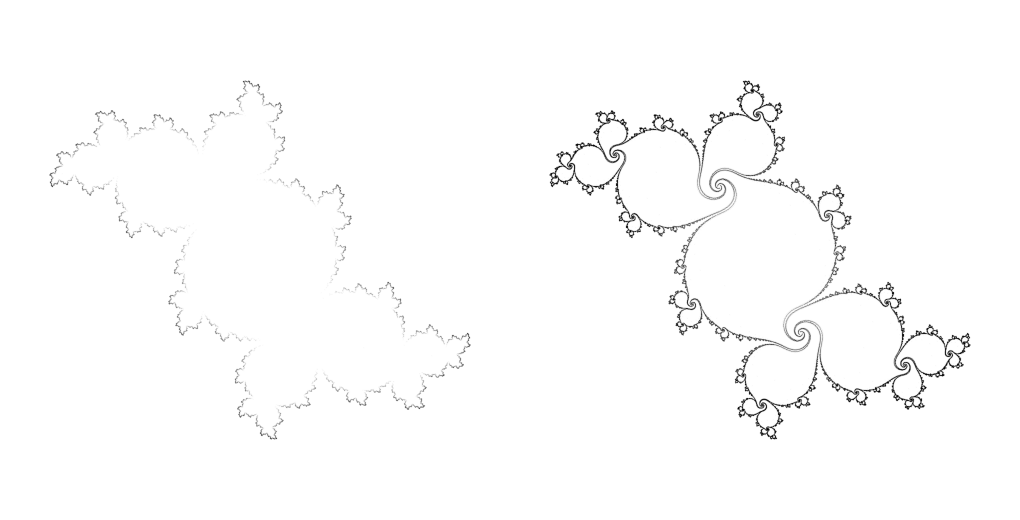

In [20]:
c = -0.11 + 0.65569999 * 1j  # 別の c で描く
r_iim = numba_julia_set_count(c, 1000000)
r_miim = numba_julia_set_count_miim(c, 1000000)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
fig.subplots_adjust(0, 0, 1, 1, 0, 0)
axes[0].imshow(np.log10(r_iim + 1), cmap="gray_r")
axes[1].imshow(r_miim, cmap="gray_r")
for ax in axes:
    ax.set_aspect("equal")
    ax.axis("off")

## 実行時間の比較

この環境(Python 3.14、MinGW-w64 の gcc、Core i7)で、10 万点の Julia 集合を計算した時間です。小数の付いた値は、その時々で変わるので目安として読んでください。

| 方法 | 1 回の時間 | Python との比 |
|------|-----------|--------------|
| `py_julia_set()`(Python) | 約 85 ms | 1 |
| `cffi_julia_set()`(CFFI + C) | 約 7.7 ms | 約 11 倍速い |
| `cy_julia_set()`(Cython) | 約 5.9 ms | 約 14 倍速い |
| `numba_julia_set()`(Numba) | 約 5.9 ms | 約 14 倍速い |

回数を数える版(30 万回、格子 300×300)では、`numba_julia_set_count()` が約 5.3 ms、元の Python の関数(`py_func`)が約 228 ms でした。

C で書いた関数を呼ぶ方法は、どれも Python の十数倍速くなります。CFFI は既存の C のコードをそのまま使え、Cython は Python に近い書き方で型を指定でき、Numba は Python の関数を書き換えずにコンパイルできます。作りたいものに合わせて選んでください。


## まとめ

* Python が遅いのは、オブジェクトが値を包んでいることと、仮想マシンで 1 命令ずつ実行するため。
* C の関数は、CFFI と ctypes で呼べる。配列は連続したメモリにして、ポインタで渡す。
* Cython は Python に似たコードを C に変換する。`cdef` で型を指定すると、ループが速くなる。
* Numba は C コンパイラなしで Python の関数をコンパイルする。初回の呼び出しに時間がかかる。
* 反復のしかたを変えると、同じ計算量でも細部まで求められる。